# CONCH · GPT R2 · Background and tissue fraction

Run all cells in order. Acquisition, image processing, axis construction, inference, controls and the decision are written in this notebook. Python3.11 is used with PyTorch2.5.0, torchvision0.20.0, NumPy1.26.4, pandas2.2.2, scikit-learn1.5.2, Pillow10.4.0, pyarrow16.1.0, statsmodels0.14.2 and the pinned official CONCH library. Install CONCH from `git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62`. Your Hugging Face account must have access to the CONCH weights.

## 1. Data source / acquisition

CRC-VAL-HE-7K and the NCT reference come from the pinned public Hugging Face dataset revision. The reference selects 4,860 tiles: 540 per tissue class, using the specified parquet row groups and evenly spaced records. Stanford comes from its pinned public normalized validation archive. The code downloads the image bytes; existing downloads are reused only after identity checks.

**Environment setup before starting the kernel (Linux, Python 3.11):**

Create this shared GPT/Kimi environment before opening the notebook. Keep it separate from the primary CONCH environment, which uses different numerical-library versions.

```bash
python3.11 -m venv .venv-conch-shared
.venv-conch-shared/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-shared/bin/python -m pip install numpy==1.26.4 scipy==1.13.1 pandas==2.2.2 scikit-learn==1.5.2 Pillow==10.4.0 pyarrow==16.1.0 scikit-image==0.24.0 statsmodels==0.14.2 opencv-python-headless==4.10.0.84
.venv-conch-shared/bin/python -m pip install matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open-clip-torch==2.24.0 requests==2.34.2 regex==2026.11.9 safetensors==0.8.0 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-shared/bin/python -m pip install --no-deps "git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62"
.venv-conch-shared/bin/python -m ipykernel install --user --name conch-gpt-kimi-inline --display-name "CONCH GPT/Kimi"
```

Select **CONCH GPT/Kimi** before Run All. The CUDA 12.4 wheels require a compatible NVIDIA driver; the code also selects CPU if CUDA is unavailable. Authenticate with Hugging Face using an account that can access `MahmoodLab/conch` before the checkpoint-download cell. The `huggingface-cli login` command is provided by the pinned Hub package.

The default input directory is `inputs/` below the notebook working directory. Set `CONCH_INPUTS` before starting the kernel to reuse a shared raw-input directory. The notebook verifies its declared downloaded inputs and runs the calculations shown below, including the stated scoring or eligibility diagnostic. All analysis-specific functions are inline; the installed CONCH package is the pinned public model implementation.

The CONCH model-input transform is explicitly set to 224×224 in the scoring cell. Reference-network weights and transforms are specified in that same cell.


In [1]:
AXIS=4
AXIS_NAME='Background and tissue fraction'
CRC_SHARDS=['data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']
REFERENCE_SHARDS=[{'label': 'ADI',
  'shard': 'NCT_CRC_HE_100K-00007-of-00031-7240d4f64e3ab056.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00007-of-00031-7240d4f64e3ab056.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'ADI',
  'shard': 'NCT_CRC_HE_100K-00008-of-00031-164c2dc788d56bcd.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00008-of-00031-164c2dc788d56bcd.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'ADI',
  'shard': 'NCT_CRC_HE_100K-00009-of-00031-a88ca52bf61c4a65.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00009-of-00031-a88ca52bf61c4a65.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'BACK',
  'shard': 'NCT_CRC_HE_100K-00021-of-00031-e828a2a9aff921c7.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00021-of-00031-e828a2a9aff921c7.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'BACK',
  'shard': 'NCT_CRC_HE_100K-00022-of-00031-179504506f62afff.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00022-of-00031-179504506f62afff.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'BACK',
  'shard': 'NCT_CRC_HE_100K-00023-of-00031-0c174269fdc04fcd.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00023-of-00031-0c174269fdc04fcd.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'DEB',
  'shard': 'NCT_CRC_HE_100K-00000-of-00031-9780c9afe3d80c58.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00000-of-00031-9780c9afe3d80c58.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'DEB',
  'shard': 'NCT_CRC_HE_100K-00001-of-00031-89eb0ee8f756b1d1.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00001-of-00031-89eb0ee8f756b1d1.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'DEB',
  'shard': 'NCT_CRC_HE_100K-00002-of-00031-0ee839cd355aeab1.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00002-of-00031-0ee839cd355aeab1.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'LYM',
  'shard': 'NCT_CRC_HE_100K-00010-of-00031-10d1d039bbb1e518.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00010-of-00031-10d1d039bbb1e518.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'LYM',
  'shard': 'NCT_CRC_HE_100K-00011-of-00031-9586fd31243bcf81.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00011-of-00031-9586fd31243bcf81.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'LYM',
  'shard': 'NCT_CRC_HE_100K-00012-of-00031-68088e297e94d57f.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00012-of-00031-68088e297e94d57f.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'MUC',
  'shard': 'NCT_CRC_HE_100K-00024-of-00031-6724461c96053f0e.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00024-of-00031-6724461c96053f0e.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'MUC',
  'shard': 'NCT_CRC_HE_100K-00025-of-00031-06d3e29beab848cc.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00025-of-00031-06d3e29beab848cc.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'MUS',
  'shard': 'NCT_CRC_HE_100K-00027-of-00031-76ba1a4a6d60e4bf.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00027-of-00031-76ba1a4a6d60e4bf.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'MUS',
  'shard': 'NCT_CRC_HE_100K-00028-of-00031-6161e17b52896e1b.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00028-of-00031-6161e17b52896e1b.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'MUS',
  'shard': 'NCT_CRC_HE_100K-00029-of-00031-01d8069141f86ca7.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00029-of-00031-01d8069141f86ca7.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'NORM',
  'shard': 'NCT_CRC_HE_100K-00014-of-00031-a59185824004206f.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00014-of-00031-a59185824004206f.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'NORM',
  'shard': 'NCT_CRC_HE_100K-00015-of-00031-72d58c4f33fb37a0.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00015-of-00031-72d58c4f33fb37a0.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'STR',
  'shard': 'NCT_CRC_HE_100K-00004-of-00031-04197e7c2252e508.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00004-of-00031-04197e7c2252e508.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'STR',
  'shard': 'NCT_CRC_HE_100K-00005-of-00031-6929e3c0e6f21267.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00005-of-00031-6929e3c0e6f21267.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'TUM',
  'shard': 'NCT_CRC_HE_100K-00017-of-00031-240fc2989151d739.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00017-of-00031-240fc2989151d739.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'TUM',
  'shard': 'NCT_CRC_HE_100K-00018-of-00031-84ed50962a18a85e.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00018-of-00031-84ed50962a18a85e.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'TUM',
  'shard': 'NCT_CRC_HE_100K-00019-of-00031-e4a4c7209859272a.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00019-of-00031-e4a4c7209859272a.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180}]
AXIS_FEATURES=['rgb_r_mean',
 'rgb_g_mean',
 'rgb_b_mean',
 'rgb_r_std',
 'rgb_g_std',
 'rgb_b_std',
 'rgb_r_q10',
 'rgb_g_q10',
 'rgb_b_q10',
 'rgb_r_q90',
 'rgb_g_q90',
 'rgb_b_q90',
 'od_r_mean',
 'od_g_mean',
 'od_b_mean',
 'od_r_std',
 'od_g_std',
 'od_b_std',
 'saturation_mean',
 'saturation_std',
 'saturation_q90',
 'gray_std',
 'gray_entropy',
 'contrast_horizontal',
 'contrast_vertical',
 'edge_mean',
 'edge_std',
 'gray_mean',
 'gray_q05',
 'gray_q50',
 'gray_q95',
 'tissue_fraction',
 'white_fraction',
 'dark_fraction']

from pathlib import Path
import concurrent.futures,hashlib,io,json,os,shutil,time,zipfile
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
from huggingface_hub import hf_hub_download,hf_hub_url,get_hf_file_metadata
from sklearn.neighbors import NearestNeighbors,NearestCentroid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

INPUT=Path(os.environ.get('CONCH_INPUTS',Path.cwd()/'inputs'));INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'conch-gpt-r2-test-{AXIS:02}-outputs';OUT.mkdir(exist_ok=True)
CLASSES=['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
CLASS_MAP={'ADI':'ADI','BACK':'BACK','DEB':'DEB','LYM':'LYM','MUC':'MUC','MUS':'MUS','NORM':'NORM','STR':'STR','TUM':'TUM','NCS':'DEB','NOR':'NORM','FCT':'STR','BLD':None}
REVISION='97765ecb14bf11ce7bb8779a1097d187844a67cb'
SOURCE_REVISION='141cc09c7d4ff33d8eda562bd75169b457f71a62'
CHECKPOINT_REVISION='f9ca9f877171a28ade80228fb195ac5d79003357'
SEED=20260715

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as source:
        for block in iter(lambda:source.read(8<<20),b''):digest.update(block)
    return digest.hexdigest()

def show_figure(figure):
    output=io.BytesIO();figure.savefig(output,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=output.getvalue()));plt.close(figure)

def download(url,destination,expected_sha256=None,expected_bytes=None):
    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)
    if destination.is_file() and (expected_bytes is None or destination.stat().st_size==expected_bytes) and (expected_sha256 is None or sha256(destination)==expected_sha256):return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with requests.get(url,stream=True,timeout=120) as response:
        response.raise_for_status()
        with open(temporary,'wb') as target:
            for block in response.iter_content(8<<20):target.write(block)
    if expected_bytes is not None:assert temporary.stat().st_size==expected_bytes
    if expected_sha256 is not None:assert sha256(temporary)==expected_sha256
    temporary.replace(destination);return destination

def pinned_parquet(filename):
    url=hf_hub_url('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REVISION)
    metadata=get_hf_file_metadata(url)
    digest=metadata.etag.strip('"')
    assert len(digest)==64,'Expected a large-file SHA-256 identity'
    return download(url,INPUT/'hf_parquet'/filename,digest,metadata.size)

stanford_record=dict(url='https://huggingface.co/datasets/Path2AI/STARC-9/resolve/2c4b716dc5370c9628162ceb9190f0b92eaafd3c/Validation_data/STANFORD-CRC-HE-VAL-SMALL-NORMALIZED.zip',sha256='088281de09bfe4d57b4a8e356a99cdb9b002a08a0ff7c44910aee0b4de81d3f3',bytes=2149005637)
stanford_archive=download(stanford_record['url'],INPUT/'STANFORD-CRC-HE-VAL-SMALL-NORMALIZED.zip',stanford_record['sha256'],stanford_record['bytes'])
with concurrent.futures.ThreadPoolExecutor(max_workers=3) as pool:
    crc_paths=list(pool.map(pinned_parquet,CRC_SHARDS))
display(pd.DataFrame([dict(source='CRC-VAL',url=hf_hub_url('1aurent/NCT-CRC-HE',name,repo_type='dataset',revision=REVISION),path=str(path),sha256=sha256(path)) for name,path in zip(CRC_SHARDS,crc_paths)]+[dict(source='Stanford',url=stanford_record['url'],path=str(stanford_archive),sha256=stanford_record['sha256'])]))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,source,url,path,sha256
0,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,fc4aa78c380802f27e59a70b2f2877dc3d2b82ddc2b800...
1,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,d607ebd6b861e3aec2ae2d457993f42222393abb9bdd99...
2,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,d733e143f0c984d24262d7b98d30669a885e7a6e3fcb46...
3,Stanford,https://huggingface.co/datasets/Path2AI/STARC-...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,088281de09bfe4d57b4a8e356a99cdb9b002a08a0ff7c4...


In [2]:
class RangeFile(io.RawIOBase):
    def __init__(self, url):
        super().__init__()
        self.url, self.position, self.ranges, self.receipts = url, 0, [], []
        response = requests.get(url, headers={'Range': 'bytes=-8'}, timeout=60)
        response.raise_for_status()
        assert response.status_code == 206
        self.size = int(response.headers['Content-Range'].split('/')[-1])
        self.ranges.append((self.size - 8, response.content))

    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.position
    def seek(self, offset, whence=0):
        self.position = offset if whence == 0 else self.position + offset if whence == 1 else self.size + offset
        return self.position

    def read(self, size=-1):
        if size < 0: size = self.size - self.position
        size = min(size, self.size - self.position)
        start = self.position
        self.position += size
        if not size: return b''
        for offset, raw in self.ranges:
            if offset <= start and start + size <= offset + len(raw):
                return raw[start-offset:start-offset+size]
        assert size < 20_000_000, f'Unexpected bulk read: {size}'
        response = requests.get(self.url, headers={'Range': f'bytes={start}-{start+size-1}'}, timeout=120)
        response.raise_for_status()
        assert response.status_code == 206 and len(response.content) == size
        raw = response.content
        self.ranges.append((start, raw))
        self.receipts.append({'start': start, 'length': size, 'sha256': hashlib.sha256(raw).hexdigest(),
                              'content_range': response.headers.get('Content-Range')})
        return raw


def save_image(raw,source,source_key,label):
    encoded_hash=hashlib.sha256(raw).hexdigest()
    path=INPUT/'raw_images'/source/(encoded_hash+'.image')
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists() or sha256(path)!=encoded_hash:
        temporary=path.with_name(path.name+f'.{os.getpid()}.part');temporary.write_bytes(raw);temporary.replace(path)
    return dict(cohort=source,source_key=source_key,tile_id=encoded_hash,path=str(path),raw_label=label,encoded_sha256=encoded_hash)

crc_rows=[]
for source_name,path in zip(CRC_SHARDS,crc_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            image=example['image'];label=CLASSES[int(example['label'])]
            source_key=f'{source_name}:{group}:{index}:{image.get("path","")}'
            crc_rows.append(save_image(image['bytes'],'CRC',source_key,label))
stanford_rows=[]
with zipfile.ZipFile(stanford_archive) as archive:
    for member in sorted(archive.namelist()):
        if not member.lower().endswith(('.png','.tif','.tiff','.jpg','.jpeg')):continue
        label=Path(member).parent.name
        assert label in CLASS_MAP,label
        stanford_rows.append(save_image(archive.read(member),'Stanford',member,label))

def reference_shard(record):
    # The pinned parquet revision and declared row groups fix this bounded panel.
    stream=RangeFile(record['url'])
    parquet=pq.ParquetFile(stream)
    candidates=[]
    for group in record['row_groups']:
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            if CLASSES[int(example['label'])]!=record['label']:continue
            candidates.append((group,index,example))
    assert len(candidates)>=record['selected'],record['shard']
    selected=np.linspace(0,len(candidates)-1,record['selected'],dtype=int)
    rows=[]
    for chosen in selected:
        group,index,example=candidates[chosen]
        key=f'{record["shard"]}:{group}:{index}:{example["image"].get("path","")}'
        rows.append(save_image(example['image']['bytes'],'NCT-reference',key,record['label']))
    return rows,dict(shard=record['shard'],url=record['url'],row_groups=record['row_groups'],selected=record['selected'],range_receipts=stream.receipts)

reference_rows=[];reference_receipts=[]
reference_manifest=INPUT/'gpt2_reference_raw_manifest.json'
if reference_manifest.exists():
    cached=json.loads(reference_manifest.read_text())
    for row in cached['images']:assert sha256(row['path'])==row['encoded_sha256']
    reference_rows=cached['images'];reference_receipts=cached['requests']
else:
    with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:
        for rows,receipt in pool.map(reference_shard,REFERENCE_SHARDS):
            reference_rows.extend(rows);reference_receipts.append(receipt)
    temporary=reference_manifest.with_name(reference_manifest.name+f'.{os.getpid()}.part')
    temporary.write_text(json.dumps(dict(images=reference_rows,requests=reference_receipts),indent=2));temporary.replace(reference_manifest)
raw_index=pd.DataFrame(crc_rows+stanford_rows+reference_rows)
raw_index.to_csv(OUT/'raw_image_index.csv.gz',index=False)
display(raw_index.groupby(['cohort','raw_label']).size().unstack(fill_value=0))
assert len(crc_rows)==7180 and len(reference_rows)==4860


raw_label,ADI,BACK,BLD,DEB,FCT,LYM,MUC,MUS,NCS,NOR,NORM,STR,TUM
cohort,,,,,,,,,,,,,
CRC,1338,847,0,339,0,634,1035,592,0,0,741,421,1233
NCT-reference,540,540,0,540,0,540,540,540,0,0,540,540,540
Stanford,2000,0,2000,0,2000,2000,2000,2000,2000,2000,0,0,2000


## 2. Data processing

Deduplicate exact image content and calculate RGB, optical-density, texture, tissue and quality measurements from pixels. Preserve Stanford blood tiles during level construction, then exclude their unmatched class from model evaluation. NCS maps to DEB, NOR to NORM and FCT to STR.

In [3]:
def image_features(row):
    with PILImage.open(row.path) as image:
        rgb=np.asarray(image.convert('RGB'),dtype=np.float32)/255
        hsv=np.asarray(image.convert('HSV'),dtype=np.float32)/255
    gray=rgb@np.array([.299,.587,.114],dtype=np.float32)
    saturation=hsv[...,1];value=hsv[...,2]
    od=-np.log(np.clip(rgb,1/255,1))
    dx=np.diff(gray,axis=1);dy=np.diff(gray,axis=0)
    edge=np.sqrt(dx[:-1,:]**2+dy[:,:-1]**2)
    padded=np.pad(gray,1,mode='reflect')
    lap=padded[:-2,1:-1]+padded[2:,1:-1]+padded[1:-1,:-2]+padded[1:-1,2:]-4*gray
    histogram=np.histogram(gray,bins=64,range=(0,1))[0].astype(float)
    probability=histogram[histogram>0]/histogram.sum()
    power=np.abs(np.fft.fftshift(np.fft.fft2(gray-gray.mean())))**2
    yy,xx=np.indices(gray.shape);radius=np.hypot(yy-gray.shape[0]/2,xx-gray.shape[1]/2)/(max(gray.shape)/2)
    h_bound=np.abs(dx[:,7::8]).mean();v_bound=np.abs(dy[7::8,:]).mean()
    h_inner=np.abs(np.delete(dx,np.arange(7,dx.shape[1],8),axis=1)).mean()
    v_inner=np.abs(np.delete(dy,np.arange(7,dy.shape[0],8),axis=0)).mean()
    result=dict(tile_id=row.tile_id,cohort=row.cohort,gray_std=float(gray.std()),gray_entropy=float(-(probability*np.log2(probability)).sum()),contrast_horizontal=float(np.abs(dx).mean()),contrast_vertical=float(np.abs(dy).mean()),edge_mean=float(edge.mean()),edge_std=float(edge.std()),gray_mean=float(gray.mean()),gray_q05=float(np.quantile(gray,.05)),gray_q50=float(np.quantile(gray,.5)),gray_q95=float(np.quantile(gray,.95)),saturation_mean=float(saturation.mean()),saturation_std=float(saturation.std()),saturation_q90=float(np.quantile(saturation,.9)),tissue_fraction=float(((saturation>.08)&(value<.92)).mean()),white_fraction=float((value>.95).mean()),dark_fraction=float((gray<.1).mean()),laplacian_variance=float(lap.var()),hf_power_ratio=float(power[radius>.5].sum()/(power.sum()+1e-12)),jpeg_blockiness=float((h_bound+v_bound)/(h_inner+v_inner+1e-12)))
    for index,channel in enumerate('rgb'):
        result.update({f'rgb_{channel}_mean':float(rgb[...,index].mean()),f'rgb_{channel}_std':float(rgb[...,index].std()),f'rgb_{channel}_q10':float(np.quantile(rgb[...,index],.1)),f'rgb_{channel}_q90':float(np.quantile(rgb[...,index],.9)),f'od_{channel}_mean':float(od[...,index].mean()),f'od_{channel}_std':float(od[...,index].std())})
    return result

# Deduplicate encoded content within cohorts before calculating features.
index=raw_index.drop_duplicates(['cohort','encoded_sha256']).reset_index(drop=True)
print('Exact duplicate exclusions:',len(raw_index)-len(index))
index['label']=index.raw_label.map(CLASS_MAP)
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as pool:
    features=pd.DataFrame(pool.map(image_features,index.itertuples(index=False)))
data=index.merge(features,on=['cohort','tile_id'],validate='one_to_one')
assert np.isfinite(data[AXIS_FEATURES].to_numpy()).all()
data.to_parquet(OUT/'image_features.parquet',index=False)
display(data.groupby('cohort').size().rename('Unique images'))


Exact duplicate exclusions: 51


cohort
CRC               7180
NCT-reference     4860
Stanford         17949
Name: Unique images, dtype: int64

## 3. Axis definition and level construction

Fit robust feature scaling on the NCT reference: median and IQR/1.349, clipped to ±10. The joint axis is mean standardized distance to the ten nearest reference tiles divided by the square root of the feature count. Construct five equal-count levels separately within each cohort, with content hash breaking ties. Sharpness, high-frequency power and JPEG blockiness are excluded from the distance and retained as controls. Stain and composition summaries are also shown separately.

In [4]:
reference_data=data[data.cohort=='NCT-reference'].copy()
targets=data[data.cohort!='NCT-reference'].copy()
def fit_scale(columns):
    matrix=reference_data[columns].to_numpy(float)
    center=np.median(matrix,axis=0)
    scale=(np.quantile(matrix,.75,axis=0)-np.quantile(matrix,.25,axis=0))/1.349
    scale[scale<1e-8]=1
    return center,scale
def transform(frame,columns,center,scale):return np.clip((frame[columns].to_numpy(float)-center)/scale,-10,10)
center,scale=fit_scale(AXIS_FEATURES)
reference_matrix=transform(reference_data,AXIS_FEATURES,center,scale)
neighbors=NearestNeighbors(n_neighbors=10,n_jobs=4).fit(reference_matrix)
targets['distance']=neighbors.kneighbors(transform(targets,AXIS_FEATURES,center,scale))[0].mean(axis=1)/np.sqrt(len(AXIS_FEATURES))
groups={'stain_distance':[column for column in AXIS_FEATURES if column.startswith(('rgb_','od_','saturation_'))], 'texture_distance':['gray_std','gray_entropy','contrast_horizontal','contrast_vertical','edge_mean','edge_std'],'composition_distance':['gray_mean','gray_q05','gray_q50','gray_q95','tissue_fraction','white_fraction','dark_fraction']}
for name,columns in groups.items():
    local_center,local_scale=fit_scale(columns)
    targets[name]=np.sqrt(np.mean(transform(targets,columns,local_center,local_scale)**2,axis=1))
targets['level']=0
for cohort,group in targets.groupby('cohort'):
    ordered=group.sort_values(['distance','tile_id'],kind='stable').index
    targets.loc[ordered,'level']=1+np.floor(np.arange(len(ordered))*5/len(ordered)).astype(int)
targets['level']=targets.level.astype(int)
assert targets.level.between(1,5).all()
targets.to_parquet(OUT/'level_assignments.parquet',index=False)
order=targets.groupby(['cohort','level']).agg(images=('tile_id','size'),distance=('distance','median'),stain=('stain_distance','median'),texture=('texture_distance','median'),composition=('composition_distance','median'),sharpness=('laplacian_variance','median'),compression=('jpeg_blockiness','median'),tissue=('tissue_fraction','mean'))
display(order);order.to_csv(OUT/'measured_axis_order.csv')
evaluation=targets[targets.label.notna()].copy()
display(evaluation.groupby(['cohort','level','label']).size().unstack(fill_value=0))


images  distance     stain   texture  composition  sharpness  \
cohort   level                                                                 
CRC      1        1436  0.184961  0.756218  0.440717     0.649238   0.010780   
         2        1436  0.235260  0.801002  0.576657     0.791751   0.012373   
         3        1436  0.288376  1.079277  0.894156     1.178911   0.013775   
         4        1436  0.388450  1.332474  1.052058     2.149973   0.009408   
         5        1436  0.674991  2.081173  1.291042     3.851197   0.005385   
Stanford 1        3590  0.313515  0.899174  0.478494     0.696908   0.006717   
         2        3590  0.360819  1.007148  0.627319     0.816600   0.006114   
         3        3590  0.407914  1.070327  0.705447     0.951192   0.005932   
         4        3590  0.487491  1.059662  0.736321     1.374320   0.006381   
         5        3589  0.652644  1.437532  0.893245     2.837958   0.005769   

                compression    tissue  
cohort   level                         
CRC      1         0.996963  0.884256  
         2         0.995638  0.861774  
         3         0.997000  0.801014  
         4         0.991929  0.609000  
         5         0.999369  0.589300  
Stanford 1         1.154505  0.921267  
         2         1.161013  0.883459  
         3         1.158630  0.824322  
         4         1.170404  0.769853  
         5         1.234527  0.602821

label            ADI  BACK  DEB  LYM  MUC  MUS  NORM  STR  TUM
cohort   level                                                
CRC      1         0     0   78  209    7   85   413   90  554
         2        27   100   72  139  140  270   181  148  359
         3       221   212    9  129  377  103    87  143  155
         4       576   116    0  124  365   71    58   27   99
         5       514   419  180   33  146   63     2   13   66
Stanford 1        94     0  758   55   32  412   421  452  683
         2       146     0  348  363   49  629   604  404  509
         3       256     0  347  575  170  525   544  494  353
         4       307     0  294  537  827  301   321  456  315
         5      1197     0  253  468  877  132   110  194  139

## 4. Model results or released scores

Load the official CONCH checkpoint and prompt ensemble and run zero-shot image classification. CONCH is not fine-tuned. Fit the displayed fixed reference classifiers only on NCT images: handcrafted centroid/logistic and a frozen ImageNet ResNet18 encoder with logistic head. All methods score the same evaluation tiles.

In [5]:
import torch
import torchvision.models as models
from torchvision import transforms
from conch.open_clip_custom import create_model_from_pretrained
from conch.downstream.zeroshot_path import zero_shot_classifier
torch.set_num_threads(4)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
checkpoint=INPUT/'conch_checkpoint/pytorch_model.bin'
if not checkpoint.exists() or sha256(checkpoint)!='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c':
    checkpoint=Path(hf_hub_download('MahmoodLab/conch','pytorch_model.bin',revision=CHECKPOINT_REVISION))
assert sha256(checkpoint)=='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c'
prompt_path=download(f'https://raw.githubusercontent.com/mahmoodlab/CONCH/{SOURCE_REVISION}/prompts/crc100k_prompts_all_per_class.json',INPUT/'crc100k_prompts_all_per_class.json','5cac7ab39a593e10d053647842401eae00b94351bd33c5edcad29b17757343e2')
prompt=json.loads(prompt_path.read_text())['0']
conch,preprocess=create_model_from_pretrained('conch_ViT-B-16',str(checkpoint),device=DEVICE,force_image_size=224)
conch.eval()
text_weights=zero_shot_classifier(conch,[prompt['classnames'][name] for name in CLASSES],prompt['templates'],device=DEVICE)

@torch.inference_mode()
def image_embeddings(frame,model,preprocess,is_conch=False):
    values=[]
    for start in range(0,len(frame),64):
        batch=[]
        for path in frame.path.iloc[start:start+64]:
            with PILImage.open(path) as image:batch.append(preprocess(image.convert('RGB')))
        tensor=torch.stack(batch).to(DEVICE)
        encoded=model.encode_image(tensor,proj_contrast=True,normalize=True) if is_conch else model(tensor)
        values.append(encoded.cpu().numpy())
    return np.concatenate(values)

conch_embedding=image_embeddings(evaluation,conch,preprocess,True)
logits=float(conch.logit_scale.exp().detach().cpu())*conch_embedding@text_weights.detach().cpu().numpy()
predictions=evaluation[['cohort','tile_id','label','level','distance','stain_distance','texture_distance','composition_distance','laplacian_variance','hf_power_ratio','jpeg_blockiness','tissue_fraction']].copy()
predictions['CONCH']=np.asarray(CLASSES)[logits.argmax(axis=1)]
np.save(OUT/'conch_logits.npy',logits)
del conch;torch.cuda.empty_cache()

# These references are fitted only to the NCT panel; evaluated images never train them.
reference_columns=AXIS_FEATURES+['laplacian_variance','hf_power_ratio','jpeg_blockiness']
ref_center,ref_scale=fit_scale(reference_columns)
x_train=transform(reference_data,reference_columns,ref_center,ref_scale)
x_test=transform(evaluation,reference_columns,ref_center,ref_scale)
y_train=reference_data.label.to_numpy()
centroid=NearestCentroid().fit(x_train,y_train)
logistic=LogisticRegression(C=1,max_iter=2000,solver='lbfgs',random_state=SEED).fit(x_train,y_train)
predictions['Handcrafted centroid']=centroid.predict(x_test)
predictions['Handcrafted logistic']=logistic.predict(x_test)
weight=download('https://download.pytorch.org/models/resnet18-f37072fd.pth',INPUT/'resnet18-f37072fd.pth','f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec',46830571)
encoder=models.resnet18(weights=None);encoder.load_state_dict(torch.load(weight,map_location='cpu',weights_only=True));encoder.fc=torch.nn.Identity();encoder=encoder.to(DEVICE).eval()
pre_resnet=models.ResNet18_Weights.IMAGENET1K_V1.transforms()
train_embedding=image_embeddings(reference_data,encoder,pre_resnet)
test_embedding=image_embeddings(evaluation,encoder,pre_resnet)
probe=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000,solver='lbfgs',random_state=SEED)).fit(train_embedding,y_train)
predictions['ResNet18 logistic']=probe.predict(test_embedding)
np.save(OUT/'reference_embeddings.npy',train_embedding);np.save(OUT/'evaluation_embeddings.npy',test_embedding)
predictions.to_parquet(OUT/'per_image_predictions.parquet',index=False)
METHODS=['CONCH','Handcrafted centroid','Handcrafted logistic','ResNet18 logistic']
display(predictions.groupby('cohort').size().rename('Scored images'))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/conch/open_clip_custom/factory.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental featur

cohort
CRC          7180
Stanford    15951
Name: Scored images, dtype: int64

## 5. Curves and controls

Calculate balanced accuracy and class-stratified tile bootstrap intervals, paired model contrasts, within-class recall, and class-adjusted correctness regressions. The fully adjusted model includes stain, sharpness, frequency, compression and tissue controls. The final panels focus on this notebook’s candidate or control.

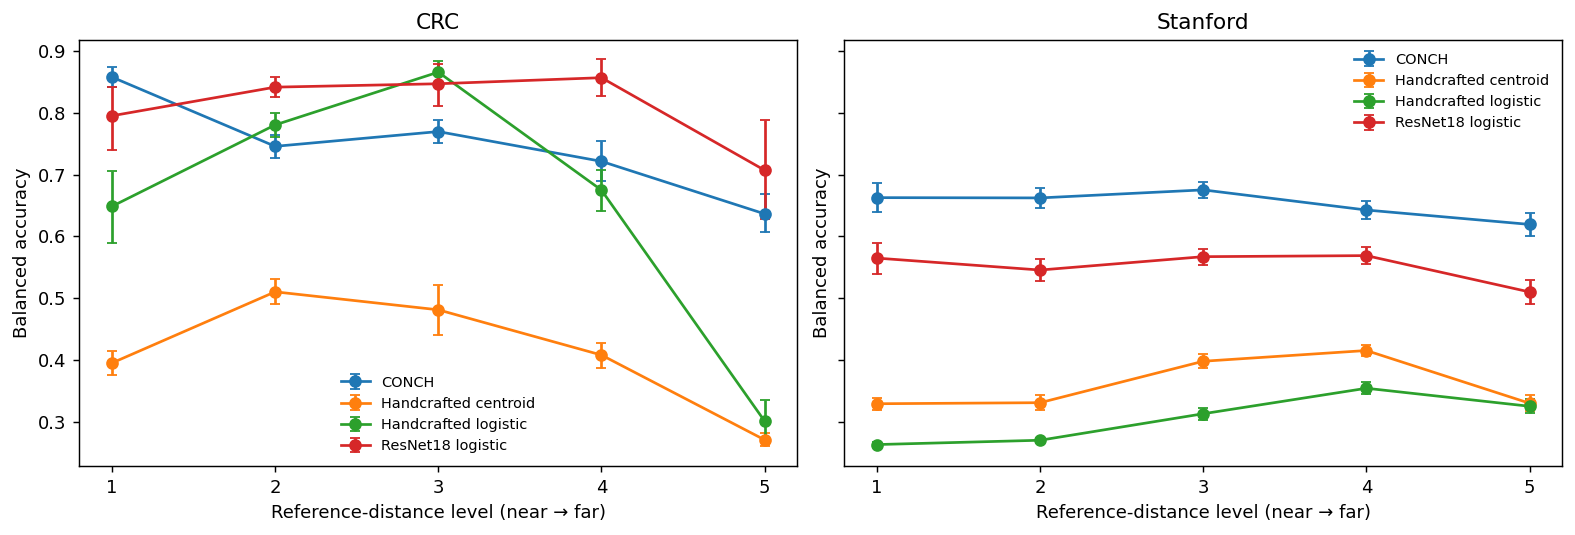

,cohort,method,drop,low,high,classes
0,CRC,CONCH,0.260712,0.216188,0.301202,7
1,CRC,Handcrafted centroid,0.303690,0.280804,0.326583,7
2,CRC,Handcrafted logistic,0.461992,0.390084,0.530553,7
3,CRC,ResNet18 logistic,0.160812,0.042183,0.274065,7
4,CRC,CONCH minus Handcrafted centroid,-0.042978,-0.091316,0.004109,7
5,CRC,CONCH minus Handcrafted logistic,-0.201280,-0.270347,-0.131004,7
6,CRC,CONCH minus ResNet18 logistic,0.099900,-0.018566,0.222929,7
7,Stanford,CONCH,0.043367,0.011684,0.073626,8
8,Stanford,Handcrafted centroid,-0.000815,-0.017126,0.014811,8
9,Stanford,Handcrafted logistic,-0.062028,-0.073914,-0.050704,8


,cohort,model,term,beta,odds_ratio,low,high,p
0,CRC,Class adjusted,ordered_level,-0.306317,0.736153,0.675548,0.802195,2.787218e-12
1,CRC,Fully adjusted,ordered_level,-0.103411,0.901756,0.812564,1.000739,5.164619e-02
2,CRC,Fully adjusted,stain_distance,-0.433632,0.648151,0.554711,0.757330,4.775954e-08
3,CRC,Fully adjusted,log_sharpness,0.729411,2.073858,1.842282,2.334544,1.451016e-33
4,CRC,Fully adjusted,hf_power_ratio,-0.304085,0.737798,0.665246,0.818262,8.525264e-09
5,CRC,Fully adjusted,jpeg_blockiness,0.007153,1.007179,0.956717,1.060302,7.850422e-01
6,CRC,Fully adjusted,tissue_fraction,0.458351,1.581464,1.281485,1.951665,1.944924e-05
7,Stanford,Class adjusted,ordered_level,-0.197678,0.820634,0.782114,0.861051,7.700123e-16
8,Stanford,Fully adjusted,ordered_level,-0.280147,0.755673,0.714003,0.799775,3.663153e-22
9,Stanford,Fully adjusted,stain_distance,0.327743,1.387833,1.286636,1.496988,2.170029e-17


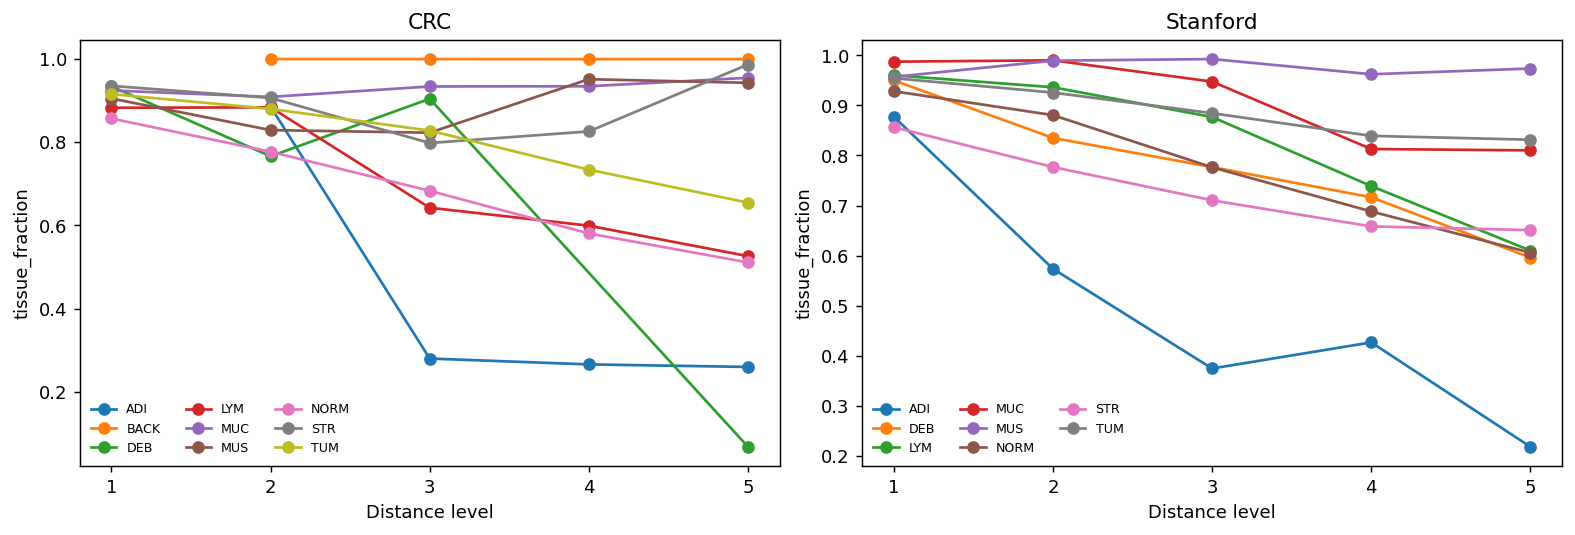

level                  1         2         3         4         5
cohort   label                                                  
CRC      ADI         NaN  0.925926  0.968326  0.970486  0.976654
         BACK        NaN  0.090000  0.344340  0.560345  0.570406
         DEB    1.000000  0.986111  1.000000       NaN  0.844444
         LYM    1.000000  0.992806  0.992248  0.991935  1.000000
         MUC    1.000000  1.000000  0.997347  0.980822  0.938356
         MUS    0.964706  0.892593  0.941748  0.985915  0.984127
         NORM   0.874092  0.740331  0.586207  0.551724  0.000000
         STR    0.388889  0.385135  0.503497  0.407407  0.307692
         TUM    0.777978  0.699164  0.593548  0.323232  0.106061
Stanford ADI    0.755319  0.753425  0.886719  0.807818  0.655806
         DEB    0.692612  0.591954  0.587896  0.551020  0.719368
         LYM    0.927273  0.942149  0.968696  0.990689  0.950855
         MUC    0.781250  0.918367  0.911765  0.945586  0.916762
         MUS    0.754854  0.750397  0.716190  0.611296  0.515152
         NORM   0.881235  0.880795  0.900735  0.856698  0.872727
         STR    0.002212  0.004950  0.002024  0.000000  0.000000
         TUM    0.506589  0.455796  0.427762  0.377778  0.323741

In [6]:
import statsmodels.api as sm
from scipy.stats import spearmanr
from sklearn.metrics import f1_score
BOOTSTRAPS=5000

def balanced_accuracy(frame,method):
    return float(np.mean([(group[method]==group.label).mean() for _,group in frame.groupby('label')]))

def bootstrap_bacc(frame,methods,rng):
    # The same class-stratified resamples are used for every model comparison.
    sums=np.zeros((BOOTSTRAPS,len(methods)))
    classes=sorted(frame.label.unique())
    for label in classes:
        group=frame[frame.label==label]
        correct=np.column_stack([(group[method]==group.label).to_numpy(dtype=float) for method in methods])
        for start in range(0,BOOTSTRAPS,100):
            stop=min(start+100,BOOTSTRAPS)
            sample=rng.integers(0,len(group),(stop-start,len(group)))
            sums[start:stop]+=correct[sample].mean(axis=1)
    return sums/len(classes)

rng=np.random.default_rng(SEED);curve_rows=[];effect_rows=[];within=[];regressions=[]
for cohort,frame in predictions.groupby('cohort'):
    # Use the same classes at both extremes for the paired endpoint.
    low=frame[frame.level==1];high=frame[frame.level==5]
    common=set(low.label)&set(high.label)
    low=low[low.label.isin(common)];high=high[high.label.isin(common)]
    drops=bootstrap_bacc(low,METHODS,rng)-bootstrap_bacc(high,METHODS,rng)
    for index,method in enumerate(METHODS):
        lo,hi=np.quantile(drops[:,index],[.025,.975])
        effect_rows.append(dict(cohort=cohort,method=method,drop=balanced_accuracy(low,method)-balanced_accuracy(high,method),low=lo,high=hi,classes=len(common)))
    for index,method in enumerate(METHODS[1:],1):
        difference=drops[:,0]-drops[:,index];lo,hi=np.quantile(difference,[.025,.975])
        effect_rows.append(dict(cohort=cohort,method='CONCH minus '+method,drop=(balanced_accuracy(low,'CONCH')-balanced_accuracy(high,'CONCH'))-(balanced_accuracy(low,method)-balanced_accuracy(high,method)),low=lo,high=hi,classes=len(common)))
    for level,group in frame.groupby('level'):
        boot=bootstrap_bacc(group,METHODS,rng)
        for index,method in enumerate(METHODS):
            lo,hi=np.quantile(boot[:,index],[.025,.975])
            curve_rows.append(dict(cohort=cohort,method=method,level=level,n=len(group),distance=group.distance.median(),balanced_accuracy=balanced_accuracy(group,method),low=lo,high=hi,macro_f1=f1_score(group.label,group[method],average='macro')))
            for label,cell in group.groupby('label'):
                within.append(dict(cohort=cohort,method=method,level=level,label=label,n=len(cell),recall=float((cell[method]==cell.label).mean())))
    features=pd.DataFrame({'ordered_level':(frame.level-frame.level.mean())/frame.level.std(),'stain_distance':frame.stain_distance,'log_sharpness':np.log(frame.laplacian_variance+1e-9),'hf_power_ratio':frame.hf_power_ratio,'jpeg_blockiness':frame.jpeg_blockiness,'tissue_fraction':frame.tissue_fraction},index=frame.index)
    for name,columns in [('Class adjusted',['ordered_level']),('Fully adjusted',list(features))]:
        x=features[columns].copy()
        for column in columns:
            std=x[column].std()
            if std>0:x[column]=(x[column]-x[column].mean())/std
        x=pd.concat([x,pd.get_dummies(frame.label,prefix='class',drop_first=True,dtype=float)],axis=1)
        x=sm.add_constant(x).astype(float)
        fit=sm.GLM((frame.CONCH==frame.label).astype(float),x,family=sm.families.Binomial()).fit()
        for term in columns:
            lo,hi=fit.conf_int().loc[term]
            regressions.append(dict(cohort=cohort,model=name,term=term,beta=fit.params[term],odds_ratio=np.exp(fit.params[term]),low=np.exp(lo),high=np.exp(hi),p=fit.pvalues[term]))
curves=pd.DataFrame(curve_rows);effects=pd.DataFrame(effect_rows);within_class=pd.DataFrame(within);adjusted=pd.DataFrame(regressions)
for filename,table in [('curves.csv',curves),('extreme_contrasts.csv',effects),('within_class.csv',within_class),('adjusted_controls.csv',adjusted)]:table.to_csv(OUT/filename,index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True,constrained_layout=True)
for ax,(cohort,frame) in zip(axes,curves.groupby('cohort')):
    for method,group in frame.groupby('method',sort=False):
        ax.errorbar(group.level,group.balanced_accuracy,yerr=[group.balanced_accuracy-group.low,group.high-group.balanced_accuracy],marker='o',capsize=3,label=method)
    ax.set(title=cohort,xlabel='Reference-distance level (near → far)',ylabel='Balanced accuracy',xticks=range(1,6));ax.legend(fontsize=8,frameon=False)
show_figure(fig);display(effects);display(adjusted)

FOCUS={1:'distance',2:'stain_distance',3:'laplacian_variance',4:'tissue_fraction',5:'jpeg_blockiness',7:'distance'}[AXIS]
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,(cohort,frame) in zip(axes,predictions.groupby('cohort')):
    for label,group in frame.groupby('label'):
        means=group.groupby('level')[FOCUS].median()
        ax.plot(means.index,means.values,marker='o',label=label)
    ax.set(title=cohort,xlabel='Distance level',ylabel=FOCUS,xticks=range(1,6));ax.legend(fontsize=7,ncol=3,frameon=False)
show_figure(fig)
display(within_class[within_class.method=='CONCH'].pivot(index=['cohort','label'],columns='level',values='recall'))


## 6. Decision and reason

In [7]:
primary=effects[(effects.cohort=='CRC')&(effects.method=='CONCH')].iloc[0]
confirmation=effects[(effects.cohort=='Stanford')&(effects.method=='CONCH')].iloc[0]
trend=adjusted[(adjusted.model=='Class adjusted')&(adjusted.term=='ordered_level')]
supported=primary.low>0 and confirmation.low>0 and (trend.beta<0).all()
if AXIS in [1,7]:
    decision='Accept the reference-distance association with independent cohort confirmation' if supported else 'Reject a confirmed reference-distance finding under the stated criteria'
    display(Markdown(f'**{decision}.** The near-minus-far CONCH balanced-accuracy drop is {100*primary["drop"]:.2f} percentage points on CRC (95% interval {100*primary.low:.2f} to {100*primary.high:.2f}) and {100*confirmation["drop"]:.2f} on Stanford ({100*confirmation.low:.2f} to {100*confirmation.high:.2f}). The class-adjusted trends are displayed above.'))
    if AXIS==7:display(Markdown('Site is the independent confirmation stratum. The continuous axis remains reference distance; the data do not establish a causal site effect.'))
else:
    display(Markdown(f'**Retain {AXIS_NAME.lower()} as a measured control.** Its measurements, relationship to distance levels, and adjusted correctness coefficients are calculated above. It is not promoted into a separate accepted axis from these same outcomes.'))
display(Markdown('Reference-model contrasts and within-class curves show whether the sensitivity is shared and which classes contribute. Balanced accuracy handles varying class proportions. Bootstrap uncertainty is tile-level because these archives do not provide a complete patient/slide grouping.'))


**Retain background and tissue fraction as a measured control.** Its measurements, relationship to distance levels, and adjusted correctness coefficients are calculated above. It is not promoted into a separate accepted axis from these same outcomes.

Reference-model contrasts and within-class curves show whether the sensitivity is shared and which classes contribute. Balanced accuracy handles varying class proportions. Bootstrap uncertainty is tile-level because these archives do not provide a complete patient/slide grouping.

In [8]:
manifest=[dict(path=p.name,bytes=p.stat().st_size,sha256=sha256(p)) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='OUTPUT_MANIFEST.json'];(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(manifest,indent=2));print('Outputs:',OUT.resolve())


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/conch-gpt-r2/conch-gpt-r2-test-04-outputs
